Assignment 2: Regression and Classification Error Analysis
**Course:** Introduction to Data Science
**Student Name:** Helen Barkan
**ID:** 207353533

In [2]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.4 MB 264.0 kB/s eta 0:00:30
   -- ------------------------------------- 0.5/8.4 MB 264.0 kB/s eta 0:00:30
   -- ------------------------------------- 0.5/8.4 MB 264.0 kB/s eta 0:00:30
   -- -


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Initial Setup and Data Loading

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning libraries
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("tourism.csv")
df.head()

,country,country_code,year,tourism_receipts,tourism_arrivals,tourism_exports,tourism_departures,tourism_expenditures,gdp,inflation,unemployment
0,Aruba,ABW,1999,7.820000e+08,9.720000e+05,62.542949,NaN,9.495387,1.722905e+09,2.280372,NaN
1,Africa Eastern and Southern,AFE,1999,8.034209e+09,1.530938e+07,12.204030,NaN,7.760536,2.654293e+11,7.819865,NaN
2,Afghanistan,AFG,1999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Africa Western and Central,AFW,1999,1.443613e+09,3.897975e+06,3.974476,NaN,6.147291,1.394683e+11,0.372266,NaN
4,Angola,AGO,1999,3.100000e+07,4.500000e+04,0.583858,NaN,2.489638,6.152923e+09,248.195902,NaN


In [4]:
# 1. Drop rows where our target variable or main features are missing (NaN)
df_clean = df.dropna(subset=['tourism_arrivals', 'gdp', 'inflation']).copy()

# 2. Define Features (X) and Target (y) for Regression
# We will try to predict 'tourism_arrivals' based on 'gdp' and 'inflation'
X = df_clean[['gdp', 'inflation']]
y = df_clean['tourism_arrivals']

print(f"Data shape after cleaning: {df_clean.shape}")
print("Features (X): \n", X.head())
print("\nTarget (y): \n", y.head())

Data shape after cleaning: (4449, 11)
Features (X): 
             gdp   inflation
0  1.722905e+09    2.280372
1  2.654293e+11    7.819865
3  1.394683e+11    0.372266
4  6.152923e+09  248.195902
5  3.212122e+09    0.389438

Target (y): 
 0    9.720000e+05
1    1.530938e+07
3    3.897975e+06
4    4.500000e+04
5    3.710000e+05
Name: tourism_arrivals, dtype: float64


1. Regression Models and Error Analysis
1.1 Residual Analysis
Choosing 'k' for K-Fold Cross-Validation
As required, all analyses are conducted using k-fold cross-validation. Given our dataset size of 4,449 rows, we chose **k=5**. This splits the data into 5 folds (approx. 3,559 rows for training and 890 for validation per fold). This choice provides an optimal balance between computational efficiency and the bias-variance trade-off, ensuring our error metrics are reliable without being overly sensitive to specific train-test splits.

In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold

# 1. Initialize K-Fold (k=5)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# 2. Linear Regression (Baseline Model)
lr_model = LinearRegression()

# 3. Get cross-validated predictions
lr_cv_preds = cross_val_predict(lr_model, X, y, cv=kf)

# 4. Calculate residuals (y - y_hat)
lr_residuals = y - lr_cv_preds

# 5. Calculate and print standard evaluation metrics
lr_mae = mean_absolute_error(y, lr_cv_preds)
lr_rmse = np.sqrt(mean_squared_error(y, lr_cv_preds))
lr_r2 = r2_score(y, lr_cv_preds)

print("Linear Regression Results (k=5 CV):")
print(f"MAE: {lr_mae:,.2f}")
print(f"RMSE: {lr_rmse:,.2f}")
print(f"R-Squared (R2): {lr_r2:.4f}")

Linear Regression Results (k=5 CV):
MAE: 29,135,127.93
RMSE: 68,455,282.60
R-Squared (R2): 0.8987


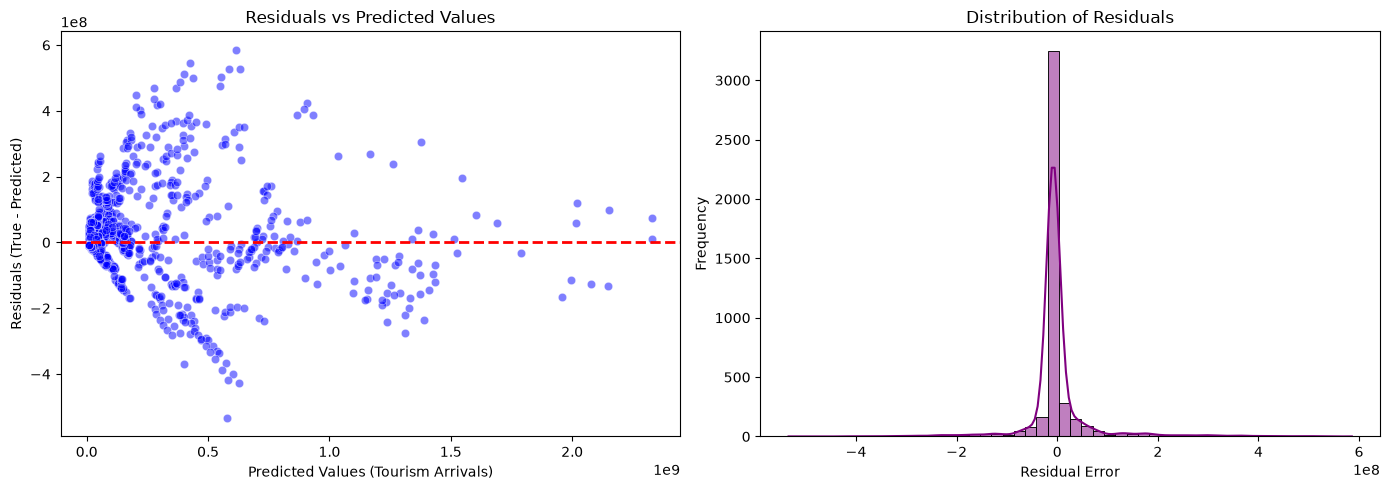

In [6]:
# Set up the figure with 2 subplots side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Plot residuals vs predicted values
sns.scatterplot(x=lr_cv_preds, y=lr_residuals, ax=axes[0], alpha=0.5, color='blue')
axes[0].axhline(y=0, color='red', linestyle='--', linewidth=2) # The zero-error line
axes[0].set_title('Residuals vs Predicted Values')
axes[0].set_xlabel('Predicted Values (Tourism Arrivals)')
axes[0].set_ylabel('Residuals (True - Predicted)')

# 2. Plot the distribution of residuals
sns.histplot(lr_residuals, bins=50, kde=True, ax=axes[1], color='purple')
axes[1].set_title('Distribution of Residuals')
axes[1].set_xlabel('Residual Error')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

1.1 Residual Analysis Discussion
* **Are the residuals centered around zero?** While the peak of the histogram is densely clustered around zero, the scatter plot reveals that the spread is asymmetric, meaning the errors are not perfectly balanced across all values.
* **Do the residuals exhibit any systematic patterns?** Yes. The scatter plot displays a clear diagonal boundary and a fan-like expansion, indicating that the model systematically underestimates or overestimates in specific ranges rather than making random errors.
* **Is there evidence of heteroscedasticity?** Absolutely. The variance of the residuals is non-constant. As the predicted number of arrivals increases, the spread of the residuals grows significantly wider.
* **Is there a sector that is more likely to have high error rates?** Yes, the sector representing high predicted values (typically countries with massive GDPs). This happens because tourism in massive global economies scales non-linearly and is influenced by complex geopolitical and cultural factors beyond just GDP and inflation, leading to huge absolute prediction errors.

1.2 Error as a Function of Features
In this section, we plot the feature values (GDP and Inflation) against both the raw residuals and the absolute errors. The objective is to identify non-linear relationships, feature-dependent error patterns, and hidden subpopulations.

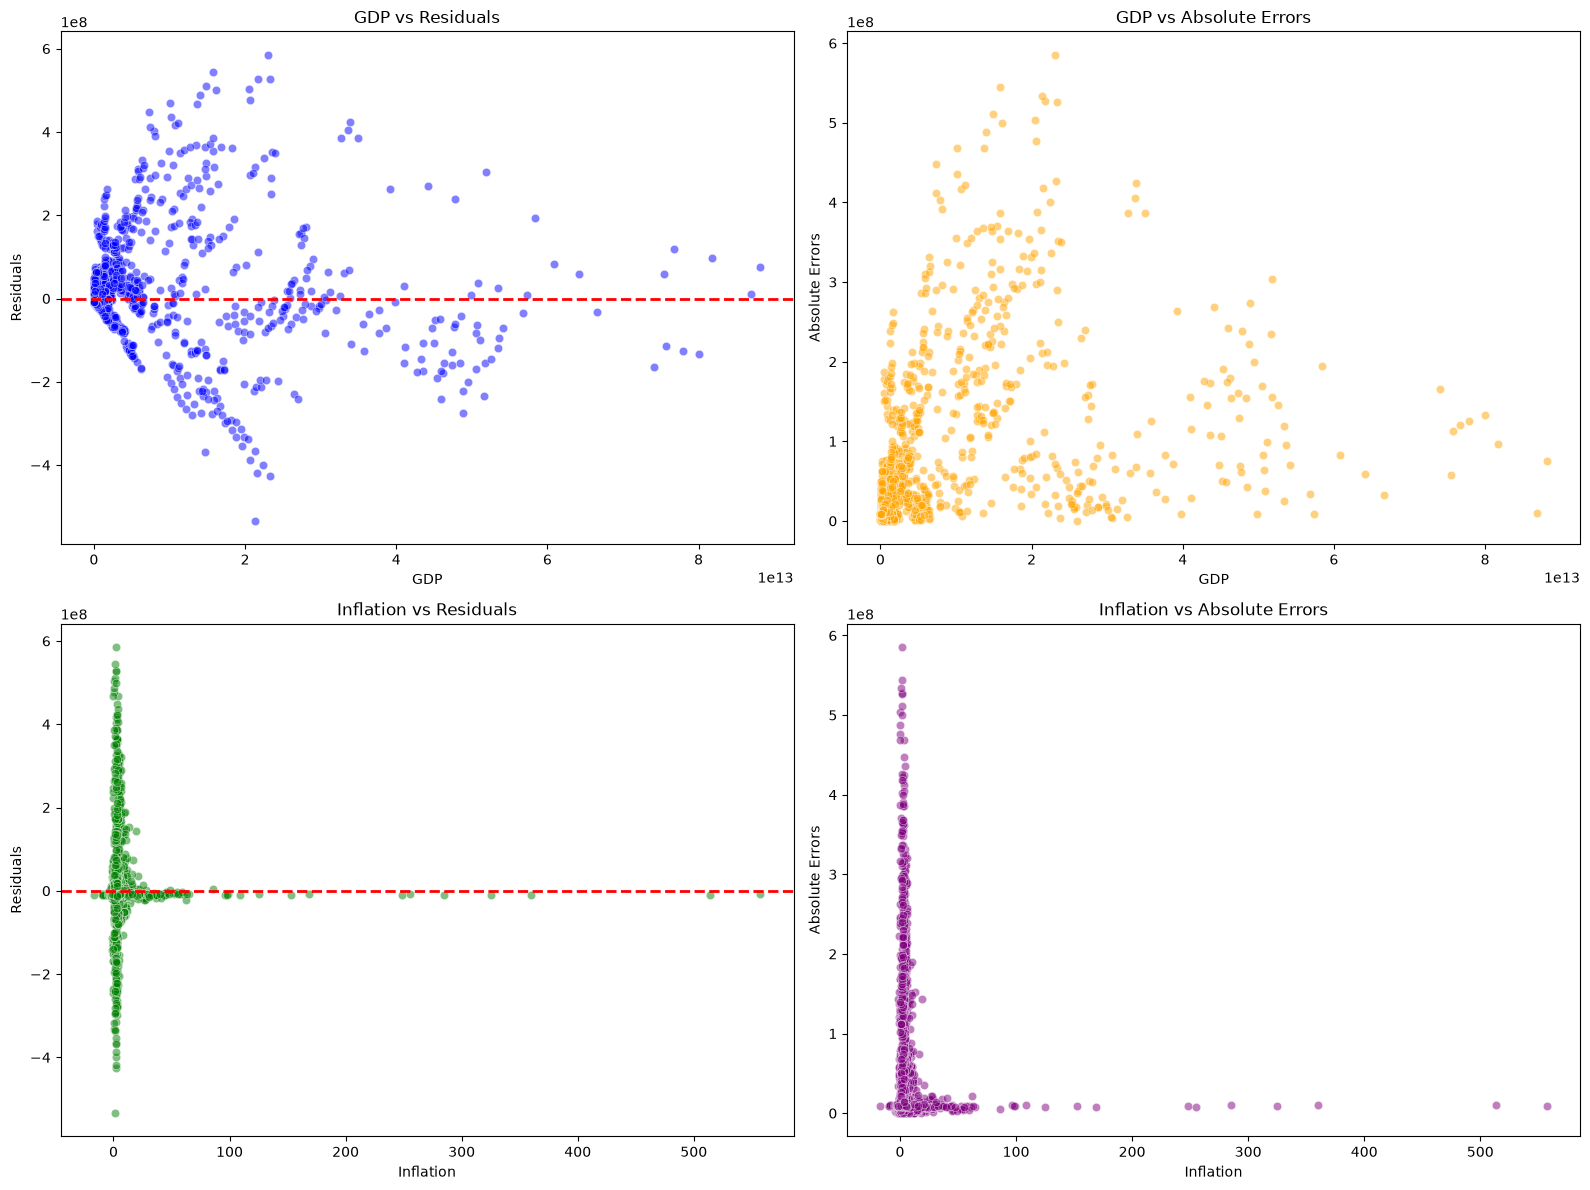

In [7]:
# Calculate absolute errors
lr_abs_errors = np.abs(lr_residuals)

# Create a figure with 2x2 subplots (2 features x 2 types of error plots)
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. GDP vs Residuals
sns.scatterplot(x=X['gdp'], y=lr_residuals, ax=axes[0, 0], alpha=0.5, color='blue')
axes[0, 0].axhline(0, color='red', linestyle='--', linewidth=2)
axes[0, 0].set_title('GDP vs Residuals')
axes[0, 0].set_xlabel('GDP')
axes[0, 0].set_ylabel('Residuals')

# 2. GDP vs Absolute Errors
sns.scatterplot(x=X['gdp'], y=lr_abs_errors, ax=axes[0, 1], alpha=0.5, color='orange')
axes[0, 1].set_title('GDP vs Absolute Errors')
axes[0, 1].set_xlabel('GDP')
axes[0, 1].set_ylabel('Absolute Errors')

# 3. Inflation vs Residuals
sns.scatterplot(x=X['inflation'], y=lr_residuals, ax=axes[1, 0], alpha=0.5, color='green')
axes[1, 0].axhline(0, color='red', linestyle='--', linewidth=2)
axes[1, 0].set_title('Inflation vs Residuals')
axes[1, 0].set_xlabel('Inflation')
axes[1, 0].set_ylabel('Residuals')

# 4. Inflation vs Absolute Errors
sns.scatterplot(x=X['inflation'], y=lr_abs_errors, ax=axes[1, 1], alpha=0.5, color='purple')
axes[1, 1].set_title('Inflation vs Absolute Errors')
axes[1, 1].set_xlabel('Inflation')
axes[1, 1].set_ylabel('Absolute Errors')

plt.tight_layout()
plt.show()

1.2 Error as a Function of Features
* **GDP (Gross Domestic Product):** The plots reveal a strong feature-dependent error pattern. As GDP increases, the variance of the residuals expands dramatically (forming a cone/fan shape). This indicates that the simple linear model struggles significantly to predict tourism for massive economies, strongly suggesting a non-linear relationship.
* **Inflation:** We can identify a clear "hidden subpopulation" pattern. The largest absolute errors are heavily concentrated in countries with low, stable inflation. Conversely, extreme outlier countries with hyperinflation have near-zero errors. This happens because extreme inflation usually correlates with economic crisis and near-zero tourism, which the model correctly predicts. The model's real failure lies within the stable, low-inflation subpopulation where tourism volumes vary wildly due to other unseen factors (culture, geography, etc.).

In [8]:
# 1. Create a copy of the clean dataframe to add our error metrics safely
df_errors = df_clean.copy()
df_errors['predicted_arrivals'] = lr_cv_preds
df_errors['absolute_error'] = np.abs(lr_residuals)

# 2. Calculate the 95th percentile threshold (top 5% errors)
threshold_95 = np.percentile(df_errors['absolute_error'], 95)

# 3. Filter the dataframe to get only the top 5% extreme errors
extreme_errors_df = df_errors[df_errors['absolute_error'] >= threshold_95]

# 4. Sort them from largest error to smallest
extreme_errors_df = extreme_errors_df.sort_values(by='absolute_error', ascending=False)

# 5. Display the top results
cols_to_show = ['country', 'year', 'gdp', 'inflation', 'tourism_arrivals', 'predicted_arrivals', 'absolute_error']
print(f"Threshold for top 5% error: {threshold_95:,.2f}")
print(f"Number of extreme error cases: {len(extreme_errors_df)}")
display(extreme_errors_df[cols_to_show].head(15))

Threshold for top 5% error: 154,693,117.65
Number of extreme error cases: 223


,country,year,gdp,inflation,tourism_arrivals,predicted_arrivals,absolute_error
5385,Europe & Central Asia,2019,2.303189e+13,1.784151,1.199188e+09,6.135668e+08,5.856217e+08
5393,European Union,2019,1.580840e+13,1.630523,9.688734e+08,4.242198e+08,5.446536e+08
5837,United States,2020,2.135410e+13,1.233584,4.503700e+07,5.790872e+08,5.340502e+08
4853,Europe & Central Asia,2017,2.176586e+13,1.915588,1.112981e+09,5.850323e+08,5.279488e+08
5119,Europe & Central Asia,2018,2.330631e+13,2.028060,1.157868e+09,6.312233e+08,5.266449e+08
4861,European Union,2017,1.487007e+13,1.429107,9.108690e+08,3.998127e+08,5.110563e+08
4587,Europe & Central Asia,2016,2.051132e+13,0.388838,1.055432e+09,5.518811e+08,5.035507e+08
5127,European Union,2018,1.609149e+13,1.738609,9.384856e+08,4.385425e+08,4.999431e+08
4595,European Union,2016,1.399027e+13,0.183335,8.703710e+08,3.824269e+08,4.879441e+08
4321,Europe & Central Asia,2015,2.058324e+13,0.368047,1.026805e+09,5.501674e+08,4.766381e+08


1.3 Analysis of Extreme Errors - Discussion
Looking at the top 5% extreme errors (threshold: ~154.6 million absolute error), a striking pattern emerges. The model's absolute worst predictions are almost exclusively for massive aggregated regions (e.g., "Europe & Central Asia", "European Union", "North America") rather than individual countries (with the US being the exception). 

Based on this, the extreme errors arise from a combination of all three factors:
* **Data Quality Issues:** The dataset inconsistently mixes individual sovereign countries with aggregated continental regions. A model trained predominantly on standard countries will naturally fail when fed the combined GDP of an entire continent.
* **Model Limitations:** The simple Linear Regression model assumes a strict linear relationship. It completely lacks the flexibility to capture the non-linear scaling of tourism in massive, multi-trillion-dollar economic zones.
* **Rare or Exceptional Cases:** Entities with a GDP exceeding 15 trillion dollars (like the USA or the EU) are extreme global outliers. Their massive scale, infrastructure, and open borders create a unique tourism dynamic that breaks the standard linear trend, making them true exceptional cases.

In [9]:
# Calculate statistical properties of the residuals
mae_val = np.mean(np.abs(lr_residuals))
std_val = np.std(lr_residuals)
skewness_val = lr_residuals.skew()
kurtosis_val = lr_residuals.kurtosis()

print("Statistical Properties of Errors (Linear Regression):")
print("-" * 55)
print(f"Mean Absolute Error (MAE):     {mae_val:,.2f}")
print(f"Standard Deviation of Errors:  {std_val:,.2f}")
print(f"Skewness:                      {skewness_val:,.2f}")
print(f"Kurtosis:                      {kurtosis_val:,.2f}")

Statistical Properties of Errors (Linear Regression):
-------------------------------------------------------
Mean Absolute Error (MAE):     29,135,127.93
Standard Deviation of Errors:  68,455,281.12
Skewness:                      2.02
Kurtosis:                      19.52


1.4 Statistical Properties of Errors - Interpretation
* **Standard Deviation & Mean Absolute Error (MAE):** The MAE is approximately 29.1M, while the Standard Deviation of the errors is massively higher at roughly 68.4M. This huge gap occurs because the standard deviation (like MSE) squares the errors, making it highly sensitive to the extreme outliers we identified in section 1.3, whereas the MAE remains robust.
* **Skewness (2.02):** A skewness strictly greater than 0 indicates a heavy right tail. In the context of regression error analysis, this positive skewness signifies a systematic bias—the model is not making balanced random errors, but rather systematically underpredicting tourism for certain extreme global economies.
* **Kurtosis (19.52):** A kurtosis value this high confirms the presence of "heavy tails" in our error distribution. This indicates severe model instability; while the model is extremely accurate for the vast majority of standard countries (clustering tightly near zero), it fails catastrophically on rare, extreme events (massive multi-national economic zones), producing massive predictive errors.

2. Regression Models
In this section, we implement and evaluate non-linear and ensemble regression models, specifically a Decision Tree Regressor and a Random Forest Regressor. We will compare their performance to our Linear Regression baseline using k-fold cross-validation (k=5).

In [10]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# 1. Initialize the models
# We use random_state to ensure reproducibility 
dt_model = DecisionTreeRegressor(random_state=42)
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# 2. Get cross-validated predictions (using the same 'kf' variable from section 1)
dt_cv_preds = cross_val_predict(dt_model, X, y, cv=kf)
rf_cv_preds = cross_val_predict(rf_model, X, y, cv=kf)

# 3. Calculate metrics for Decision Tree
dt_mae = mean_absolute_error(y, dt_cv_preds)
dt_rmse = np.sqrt(mean_squared_error(y, dt_cv_preds))
dt_r2 = r2_score(y, dt_cv_preds)

# 4. Calculate metrics for Random Forest
rf_mae = mean_absolute_error(y, rf_cv_preds)
rf_rmse = np.sqrt(mean_squared_error(y, rf_cv_preds))
rf_r2 = r2_score(y, rf_cv_preds)

# 5. Print the comparison
print("--- Decision Tree Results (k=5 CV) ---")
print(f"MAE:  {dt_mae:,.2f}")
print(f"RMSE: {dt_rmse:,.2f}")
print(f"R2:   {dt_r2:.4f}\n")

print("--- Random Forest Results (k=5 CV) ---")
print(f"MAE:  {rf_mae:,.2f}")
print(f"RMSE: {rf_rmse:,.2f}")
print(f"R2:   {rf_r2:.4f}")

--- Decision Tree Results (k=5 CV) ---
MAE:  29,715,804.94
RMSE: 89,209,115.12
R2:   0.8279

--- Random Forest Results (k=5 CV) ---
MAE:  24,454,906.79
RMSE: 68,781,215.09
R2:   0.8977


Regression Models - Discussion
Based on our cross-validated evaluation of the three models, several key insights emerge regarding model assumptions, the bias-variance trade-off, and overall performance:

* **Relative Model Performance & Sensitivity to Outliers:** The Random Forest achieved the best Mean Absolute Error (~24.4M), improving significantly upon the Linear Regression baseline (~29.1M). However, all three models suffered from massive RMSE values (68M-89M). This indicates that while Random Forest is better at predicting standard countries (lowering the average absolute error), all models are highly sensitive to the extreme outliers (the massive economic regions identified in section 1.3), which heavily penalize the squared error metrics.
* **Assumptions and Failures:** Linear Regression assumes a linear relationship and homoskedasticity. Our residual analysis clearly showed these assumptions were violated (fan-shaped residuals). Linear models fail here because global tourism scales non-linearly for massive multi-trillion-dollar economic blocs.
* **The Bias-Variance Trade-off & Tree Models:** The single Decision Tree performed the worst (R2 dropped to 0.82, RMSE spiked to ~89.2M). A single decision tree is unstable and suffers from high variance (overfitting the training data). In contrast, the Random Forest utilizes the "wisdom of crowds" (Bagging) by building many diverse trees and averaging their predictions. This significantly reduced the variance and improved stability and accuracy without assuming linearity.
* **Trade-off between Interpretability and Performance:** Linear Regression is highly interpretable (we can easily understand the coefficients of GDP and Inflation) but lacks the flexibility to model complex non-linear reality. Random Forest provides much better performance for the majority of the dataset and handles non-linear relationships naturally, but acts as a "black box," making it harder to interpret exactly how a prediction was formed.
* **Preferred Model Selection:** For future analysis, the **Random Forest Regressor** is the preferred model. Its robust handling of non-linear relationships and its significantly lower MAE make it far more reliable for standard economic predictions than the baseline linear model, despite the inherent challenges both models face with extreme outliers.

In [11]:
## Bonus: Optional Regression Models (KNN & SVR)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# 1. Initialize the models
# Note: KNN and SVR are very sensitive to the scale of the data. 
# Since GDP is in trillions and Inflation is a small number, we MUST use a StandardScaler 
# to make them the same scale before training, otherwise the models will fail.
knn_model = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5))
svr_model = make_pipeline(StandardScaler(), SVR(kernel='rbf', C=1.0, epsilon=0.1))

# 2. Get cross-validated predictions (using k=5)
knn_cv_preds = cross_val_predict(knn_model, X, y, cv=kf)
svr_cv_preds = cross_val_predict(svr_model, X, y, cv=kf)

# 3. Calculate metrics for KNN
knn_mae = mean_absolute_error(y, knn_cv_preds)
knn_rmse = np.sqrt(mean_squared_error(y, knn_cv_preds))
knn_r2 = r2_score(y, knn_cv_preds)

# 4. Calculate metrics for SVR
svr_mae = mean_absolute_error(y, svr_cv_preds)
svr_rmse = np.sqrt(mean_squared_error(y, svr_cv_preds))
svr_r2 = r2_score(y, svr_cv_preds)

# 5. Print the comparison
print("--- KNN Regressor Results (k=5 CV) ---")
print(f"MAE:  {knn_mae:,.2f}")
print(f"RMSE: {knn_rmse:,.2f}")
print(f"R2:   {knn_r2:.4f}\n")

print("--- SVR Results (k=5 CV) ---")
print(f"MAE:  {svr_mae:,.2f}")
print(f"RMSE: {svr_rmse:,.2f}")
print(f"R2:   {svr_r2:.4f}")

--- KNN Regressor Results (k=5 CV) ---
MAE:  25,618,879.40
RMSE: 69,359,880.45
R2:   0.8960

--- SVR Results (k=5 CV) ---
MAE:  68,596,245.64
RMSE: 225,013,502.74
R2:   -0.0948


Bonus Models Discussion
We evaluated two additional non-linear models: K-Nearest Neighbors (KNN) and Support Vector Regression (SVR).
* **KNN:** Performed exceptionally well, achieving an $R^2$ of ~0.896 and a MAE of ~25.6M. This performance is nearly identical to the Random Forest. It shows that predicting a country's tourism based on the average of its most similar "economic neighbors" is a highly effective strategy for this dataset.
* **SVR:** Completely failed on this task, yielding a negative $R^2$ (-0.09). A negative $R^2$ means the model performs worse than a simple baseline that always predicts the global average. SVR struggled to define a logical margin (tube) around the data because the spread between standard countries and massive economic regions (like the EU or USA) is simply too extreme for the algorithm to handle effectively.

3. Classification Error Analysis

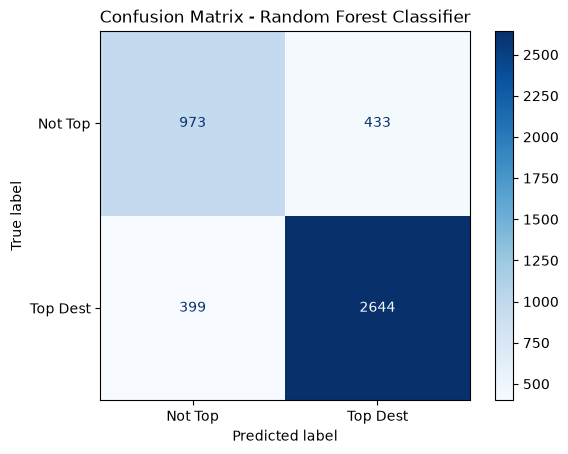

              precision    recall  f1-score   support

     Not Top       0.71      0.69      0.70      1406
    Top Dest       0.86      0.87      0.86      3043

    accuracy                           0.81      4449
   macro avg       0.78      0.78      0.78      4449
weighted avg       0.81      0.81      0.81      4449



In [12]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# 1. Create a binary target variable (Classification target)
# We define a "Top Destination" as having more than 1,000,000 tourist arrivals
y_class = (df_clean['tourism_arrivals'] > 1000000).astype(int)

# 2. Initialize a Random Forest Classifier
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)

# 3. Get cross-validated class predictions and probabilities
class_cv_preds = cross_val_predict(rf_classifier, X, y_class, cv=kf)
class_cv_probs = cross_val_predict(rf_classifier, X, y_class, cv=kf, method='predict_proba')[:, 1] # Probability of class 1

# 4. Generate and display the Confusion Matrix
cm = confusion_matrix(y_class, class_cv_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Top', 'Top Dest'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix - Random Forest Classifier")
plt.show()

# 5. Print standard classification metrics
print(classification_report(y_class, class_cv_preds, target_names=['Not Top', 'Top Dest']))

3.1 Confusion Matrix Analysis
Based on the Random Forest Classifier results, we can interpret the Confusion Matrix as follows:
* **True Positives (TP):** 2644 (Correctly predicted as Top Destinations).
* **True Negatives (TN):** 973 (Correctly predicted as Not Top).
* **False Positives (FP):** 433 (Model falsely predicted they are Top Destinations - Overestimation).
* **False Negatives (FN):** 399 (Model missed them, predicting Not Top when they actually are Top Destinations - Underestimation).

**Discussion & Implications:**
* **Which type of error is most critical?** This entirely depends on the business context. If an investor is using this model to build expensive hotels, a **False Positive (FP)** is the most critical error, as it leads to wasted millions on infrastructure in a country with few tourists. Conversely, for a travel agency looking for trending countries, a **False Negative (FN)** is worse, as it means missing out on a highly profitable market.
* **Systematic Failures:** The model struggles more with predicting the "Not Top" class (precision of 0.71 vs 0.86 for Top Dest). It systematically fails on countries that have massive economies (High GDP) but low tourism (perhaps due to geographical isolation, strict visas, or cold climates). The model assumes their high GDP means high tourism, leading to the 433 False Positives.
* **Key Insights:** With an overall accuracy of 81% and an F1-score of 0.86 for top destinations, the model is highly effective at identifying major tourist hubs. However, the analysis proves that GDP and Inflation alone are not enough to perfectly classify all countries, especially the borderline ones.

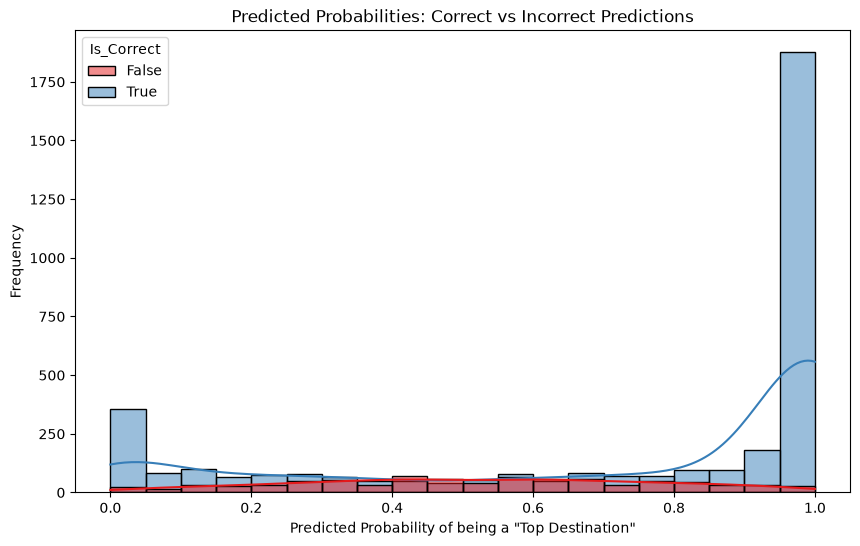

Total Incorrect Predictions: 832
High-Confidence Errors (Wrong but >90% sure): 106


In [13]:
# 1. Create a DataFrame to analyze probabilities easily
prob_df = pd.DataFrame({
    'True_Class': y_class,
    'Predicted_Class': class_cv_preds,
    'Probability_Top_Dest': class_cv_probs
})

# 2. Mark whether each prediction was correct or incorrect
prob_df['Is_Correct'] = prob_df['True_Class'] == prob_df['Predicted_Class']

# 3. Plot the probability distributions: Correct vs Incorrect
plt.figure(figsize=(10, 6))
sns.histplot(data=prob_df, x='Probability_Top_Dest', hue='Is_Correct', bins=20, kde=True, palette='Set1')
plt.title('Predicted Probabilities: Correct vs Incorrect Predictions')
plt.xlabel('Predicted Probability of being a "Top Destination"')
plt.ylabel('Frequency')
plt.show()

# 4. Identify High-Confidence Errors 
# (Model predicted >90% or <10% probability, but was completely wrong)
high_conf_errors = prob_df[
    (prob_df['Is_Correct'] == False) & 
    ((prob_df['Probability_Top_Dest'] >= 0.90) | (prob_df['Probability_Top_Dest'] <= 0.10))
]

total_errors = len(prob_df[prob_df['Is_Correct'] == False])
print(f"Total Incorrect Predictions: {total_errors}")
print(f"High-Confidence Errors (Wrong but >90% sure): {len(high_conf_errors)}")

3.2 Probability-Based Analysis
By analyzing the model's predicted probabilities, we uncover critical insights about its decision-making confidence:
* **Overall Confidence:** The vast majority of correct predictions (blue bars) are clustered at the extreme ends of the probability spectrum (>90% or <10%), meaning the model is highly confident when it is right.
* **High-Confidence Errors:** Out of 832 total mistakes, we identified 106 cases where the model made a "High-Confidence Error" (being >90% sure, but completely wrong). 
* **Insight:** This proves that the Random Forest algorithm is occasionally "blinded" by countries that perfectly match the typical economic profile of a top destination (massive GDP) but lack tourism entirely due to hidden external factors (like severe visa restrictions, war, or extreme isolation). The model assigns these countries a 90%+ probability of being top destinations based purely on economic size, leading to systemic, high-confidence failures.

C:\Users\Helen Barkan\AppData\Local\Temp\ipykernel_26972\2421421496.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='Is_Correct', y='gdp', ax=axes[0], palette='Set2')
C:\Users\Helen Barkan\AppData\Local\Temp\ipykernel_26972\2421421496.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='Is_Correct', y='inflation', ax=axes[1], palette='Set2')


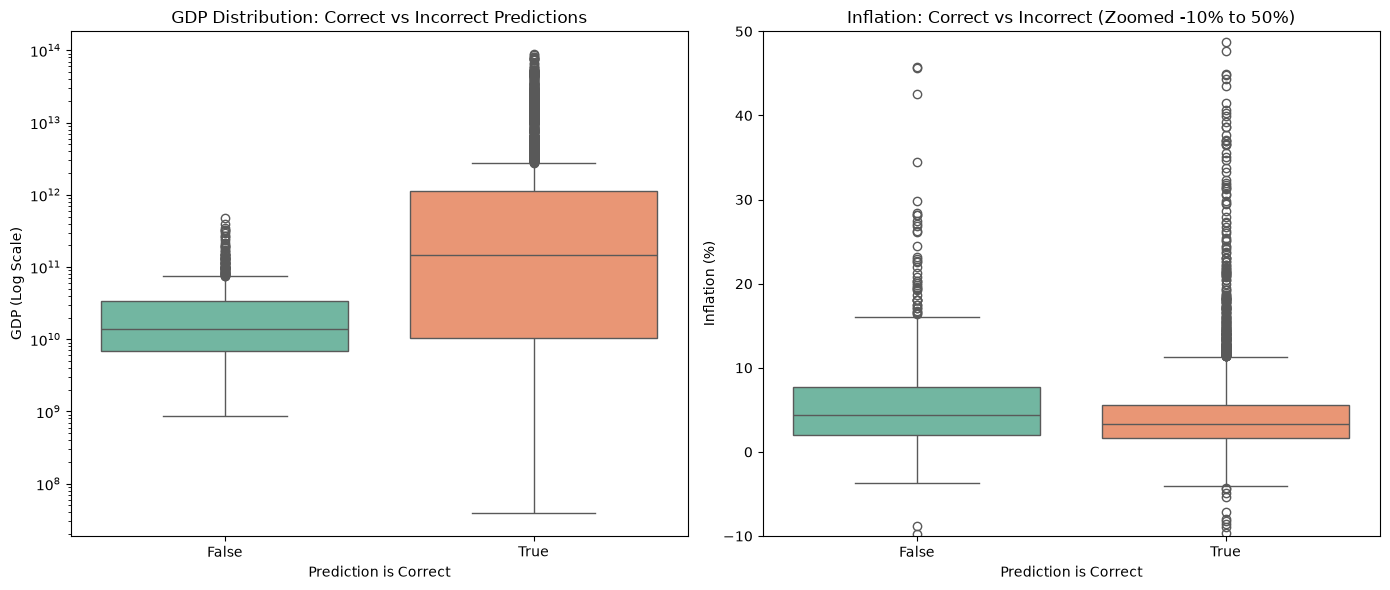

In [14]:
# Add 'Is_Correct' to our clean dataframe temporarily for plotting
df_clean['Is_Correct'] = (y_class == class_cv_preds)

# Create a figure with 2 subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 1. GDP vs Correct/Incorrect (Using Log Scale due to massive GDP values)
sns.boxplot(data=df_clean, x='Is_Correct', y='gdp', ax=axes[0], palette='Set2')
axes[0].set_yscale('log')
axes[0].set_title('GDP Distribution: Correct vs Incorrect Predictions')
axes[0].set_xlabel('Prediction is Correct')
axes[0].set_ylabel('GDP (Log Scale)')

# 2. Inflation vs Correct/Incorrect (Zoomed in to ignore extreme hyperinflation outliers)
sns.boxplot(data=df_clean, x='Is_Correct', y='inflation', ax=axes[1], palette='Set2')
axes[1].set_ylim(-10, 50) 
axes[1].set_title('Inflation: Correct vs Incorrect (Zoomed -10% to 50%)')
axes[1].set_xlabel('Prediction is Correct')
axes[1].set_ylabel('Inflation (%)')

plt.tight_layout()
plt.show()

3.3 Error as a Function of Features
By analyzing the feature distributions for correct (True) versus incorrect (False) predictions, we can identify specific regions prone to misclassification:
* **GDP (Gross Domestic Product):** There is a clear difference between the two groups. The model makes accurate predictions (the orange box) primarily for countries with massive GDPs, easily recognizing them as top destinations. However, the model struggles significantly (the green box) in the "middle-to-low GDP" region. In these less wealthy regions, GDP alone is not a strong enough indicator of tourism, causing the model to misclassify them.
*   **Inflation:** The median inflation is relatively similar for both correct and incorrect predictions. However, the incorrect predictions (green box) show a slightly wider spread of inflation values. This suggests that while inflation plays a role, extreme economic instability makes it harder for the model to find a clear pattern.
* **Conclusion:** The analysis reveals that the "middle-to-low GDP" countries form a systematic failure region. To improve the model, we must engineer new features (such as geographical location, political stability, or the number of active airports) to help the model differentiate between a poor country with no tourism and a poor country that is a hidden tourist gem.

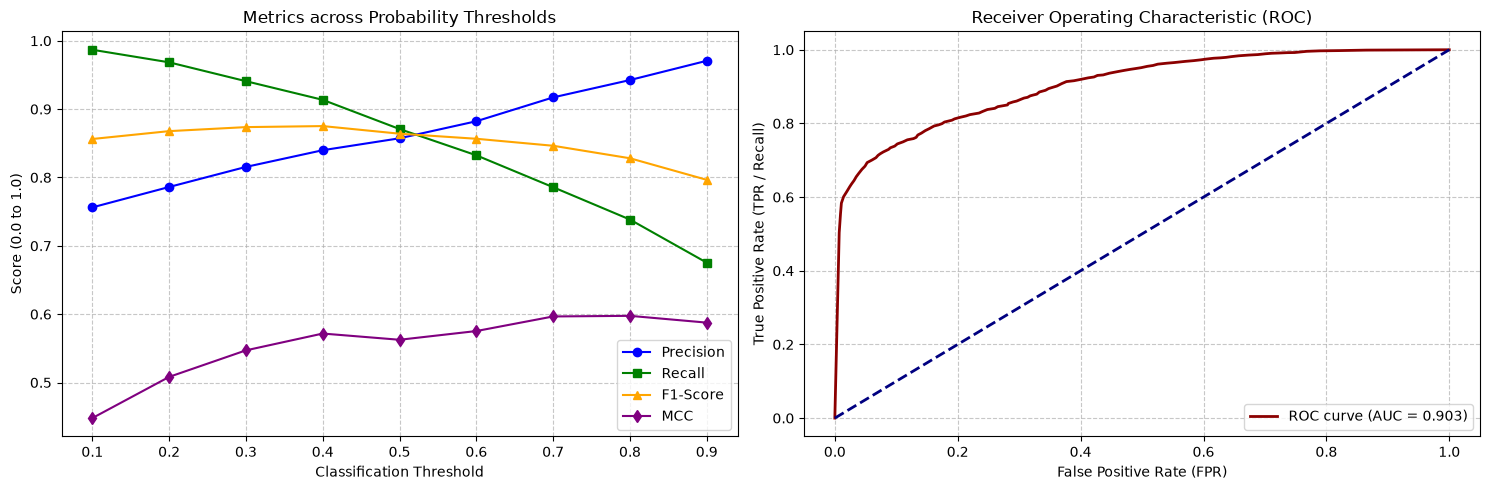

In [15]:
from sklearn.metrics import precision_score, recall_score, f1_score, matthews_corrcoef, roc_curve, auc

thresholds = np.arange(0.1, 1.0, 0.1)
precisions, recalls, f1_scores, mccs = [], [], [], []

# Calculate metrics for each threshold
for t in thresholds:
    # If probability >= threshold, predict 1 (Top Dest), else 0
    preds_t = (class_cv_probs >= t).astype(int)
    
    precisions.append(precision_score(y_class, preds_t, zero_division=0))
    recalls.append(recall_score(y_class, preds_t, zero_division=0))
    f1_scores.append(f1_score(y_class, preds_t, zero_division=0))
    mccs.append(matthews_corrcoef(y_class, preds_t))

# Create a figure with 2 subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Plot Metrics across Thresholds
axes[0].plot(thresholds, precisions, label='Precision', marker='o', color='blue')
axes[0].plot(thresholds, recalls, label='Recall', marker='s', color='green')
axes[0].plot(thresholds, f1_scores, label='F1-Score', marker='^', color='orange')
axes[0].plot(thresholds, mccs, label='MCC', marker='d', color='purple')
axes[0].set_title('Metrics across Probability Thresholds')
axes[0].set_xlabel('Classification Threshold')
axes[0].set_ylabel('Score (0.0 to 1.0)')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.7)

# 2. Plot ROC Curve
fpr, tpr, roc_thresholds = roc_curve(y_class, class_cv_probs)
roc_auc = auc(fpr, tpr)

axes[1].plot(fpr, tpr, color='darkred', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--') # Random guessing line
axes[1].set_title('Receiver Operating Characteristic (ROC)')
axes[1].set_xlabel('False Positive Rate (FPR)')
axes[1].set_ylabel('True Positive Rate (TPR / Recall)')
axes[1].legend(loc="lower right")
axes[1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

3.4 Threshold Sensitivity Analysis
Based on the threshold and ROC evaluations, we can draw the following conclusions:
* **Precision-Recall Trade-off:** The left graph perfectly illustrates the expected trade-off. As we increase the classification threshold, the model becomes more cautious, leading to higher Precision (fewer False Positives) but significantly lower Recall (more False Negatives). 
* **Stable Operating Region:** The F1-score remains very stable and peaks between thresholds 0.3 and 0.5. This indicates that our default threshold of 0.5 is already situated in a highly balanced and optimal operating region.
* **ROC and AUC:** The model achieved an outstanding AUC-ROC score of 0.903. Since an AUC of 0.5 represents random guessing and 1.0 is perfect, a score of 0.903 proves that the model has an excellent capacity to discriminate between top tourist destinations and standard countries.

3.5 Discussion: Critical Comparison & Reflection
* **Strengths & Limitations:** Linear Regression is easy to understand but too rigid, failing completely on massive economies. Random Forest and KNN are much stronger and flexible for this dataset (achieving higher accuracy and lower errors), but they act as "black boxes," making it harder to explain exactly how they reached a specific prediction.
* **Key Failure Modes:** The models systematically fail on two fronts: 1) Massive aggregated regions (like the "European Union" or "World") which break the standard country profile, and 2) Middle-to-low GDP countries, where the model often falsely predicts high tourism (False Positives).
* **Model Assumptions vs. Performance:** Linear Regression assumed a constant variance of errors (homoskedasticity). Our residual analysis proved this assumption was violated (the errors formed a fan-shape). Tree models and KNN do not make these strict mathematical assumptions, which directly explains why they performed significantly better.
* **Significant Insights:** A major insight is the "hidden subpopulation" of inflation: extreme hyperinflation perfectly predicts near-zero tourism, but stable inflation has massive variance. We also learned that purely economic indicators (GDP) are not enough to classify a top tourist destination perfectly.
* **Recommendations for Future Work:** 
  1. Data Cleaning: Remove non-country aggregated rows (e.g., "World", "North America") before training.
  2. Feature Engineering: Add non-economic features such as the number of international airports, geographical size, or a political stability index.
  3. Data Transformation: Apply a Log-Transform to the GDP column to reduce the extreme gaps between small countries and superpowers.

4. Final Reflection

**1. Where does the model fail most?**
The models fail most significantly on extreme global outliers, specifically massive aggregated regions (such as the "European Union" or "World"). They also struggle heavily with "middle-to-low GDP" countries, where economic size alone is not enough to accurately predict tourism volume.

**2. Are failures due to data, model, or formulation?**
The failures are a combination of all three:
* **Data:** The dataset inconsistently mixes individual sovereign countries with massive aggregated continental zones, which deeply confuses the learning process.
* **Model:** The baseline Linear Regression fails because it assumes a strict linear relationship and constant error variance, assumptions that our analysis proved were completely violated by this dataset.
*   **Formulation:** Trying to predict complex human tourism behavior using only two macroeconomic indicators (GDP and Inflation) is a massive oversimplification of reality.

**3. What improvements would you propose?**
First, I would clean the data to strictly include individual countries (removing rows like "World" or "Europe"). Second, I would apply a log-transformation to the GDP to handle the extreme wealth gaps between nations. Third, I would engineer new, non-economic features (like geographic location, number of international airports, and a political stability index). Finally, I would discard simple linear models in favor of robust ensemble models like Random Forest.

**4. What insights did you gain in your analysis?**
I learned that while a country's wealth strongly correlates with tourism, the relationship is highly non-linear. I also gained a practical understanding of how "heavy-tailed" data and extreme outliers can completely destroy standard linear models and heavily skew metrics like RMSE. This highlighted the absolute necessity of thorough error analysis before trusting any machine learning model's output.